In [3]:
from google.colab import auth

auth.authenticate_user()

In [4]:
PROJECT = "pi4-vacinacao-poa"

client = bigquery.Client(project=PROJECT)


In [6]:

# 3. KPIs
# -------------------------

df_kpis = client.query("""
    SELECT *
    FROM `pi4-vacinacao-poa.pni_gold.tb_visao_geral_kpis`
""").to_dataframe()

# -------------------------
# 4. Séries temporais
# -------------------------

df_series = client.query("""
    SELECT *
    FROM `pi4-vacinacao-poa.pni_gold.tb_series_temporais_doses`
""").to_dataframe()

# -------------------------
# 5. Dados espaciais
# -------------------------

df_cluster = client.query("""
    SELECT *
    FROM `pi4-vacinacao-poa.pni_gold.tb_clustering_espacial_cep`
""").to_dataframe()

In [8]:
df_kpis.head(2)

,mes_aplicacao,nome_estabelecimento,faixa_etaria,sexo_paciente,raca_cor_paciente,sigla_vacina,tipo_dose,total_doses
0,3,UNIDADE DE SAUDE NUCLEO ESPERANCA,0 a 5 anos,F,PARDA,BCG,nica,1
1,3,UNIDADE DE SAUDE COSTA E SILVA,0 a 5 anos,F,BRANCA,BCG,nica,1


In [9]:
df_series.head(2)

,data_aplicacao,ano_aplicacao,mes_aplicacao,dia_semana,sigla_vacina,tipo_dose,total_doses_aplicadas,pacientes_atendidos
0,2026-01-02,2026,1,6,BCG,nica,57,55
1,2026-01-02,2026,1,6,COV-19 PFIZER-COMIRN,Dose,107,107


In [10]:
df_cluster.head(2)

,cep_prefixo_5digitos,total_doses,total_pacientes_unicos,media_idade,doses_idosos_60mais,doses_criancas_0a5,doses_adultos_18a59,doses_sexo_feminino,doses_sexo_masculino,doses_influenza_gripe,doses_covid
0,24740,10,1,0.0,0,10,0,10,0,2,0
1,13173,10,1,0.0,0,10,0,10,0,2,0


In [13]:
from main import run

df_kpis, df_series, df_cluster = run()

Carregando BigQuery...
Preparando dados...

KPIs
Shape: (205852, 8)

Duplicados exatos:
0

Nulos:
                      nulos  percentual
mes_aplicacao             0         0.0
nome_estabelecimento      0         0.0
faixa_etaria              0         0.0
sexo_paciente             0         0.0
raca_cor_paciente         0         0.0
sigla_vacina              0         0.0
tipo_dose                 0         0.0
total_doses               0         0.0

SÉRIES TEMPORAIS
Shape: (22419, 8)

Duplicados exatos:
0

Nulos:
                       nulos  percentual
data_aplicacao             0         0.0
ano_aplicacao              0         0.0
mes_aplicacao              0         0.0
dia_semana                 0         0.0
sigla_vacina               0         0.0
tipo_dose                  0         0.0
total_doses_aplicadas      0         0.0
pacientes_atendidos        0         0.0

CLUSTER
Shape: (1102, 11)

Duplicados exatos:
0

Nulos:
                        nulos  percentual
cep_pref

A etapa de validação indicou que as três bases estão estruturalmente consistentes para continuidade da análise. A base de KPIs possui 205.852 registros, a série temporal 22.419 registros e a base destinada ao clustering 1.102 CEPs, sem valores nulos, registros duplicados, CEPs repetidos ou valores negativos nas variáveis numéricas avaliadas. A série temporal cobre o período de 1º de janeiro a 31 de julho de 2026, sem datas inválidas ou dias completamente ausentes, enquanto a base de clustering apresenta variabilidade em todas as features analisadas. Com isso, a etapa de qualidade básica dos dados pode ser considerada concluída, permitindo avançar para a análise exploratória, engenharia de atributos, clustering dos perfis de vacinação por CEP e modelagem das séries temporais. Ressalta-se apenas que, neste momento, o agrupamento é baseado nas características de vacinação associadas aos CEPs

In [14]:
from eda import (
    resumo_cluster,
    distribuicao_cluster,
    correlacao_cluster,
    top_ceps,
    ranking_vacinas,
    serie_temporal_geral,
    doses_por_dia_semana
)

In [16]:
resumo_cluster(df_cluster)


Resumo estatístico:
                         count        mean          std   min   25%   50%  \
total_doses             1102.0  915.065336   6396.95611  10.0  17.0  43.5   
total_pacientes_unicos  1102.0  606.087114  3804.677892   1.0  13.0  34.0   
media_idade             1102.0   36.715064     9.554274   0.0  31.9  37.0   
doses_idosos_60mais     1102.0  261.248639  2094.007862   0.0   2.0   7.0   
doses_criancas_0a5      1102.0  220.293103  2045.911965   0.0   1.0   5.0   
doses_adultos_18a59     1102.0  350.546279  1839.285817   0.0  10.0  28.5   
doses_sexo_feminino     1102.0  532.527223  3688.603858   0.0  10.0  24.0   
doses_sexo_masculino    1102.0  382.401996  2707.192073   0.0   8.0  19.5   
doses_influenza_gripe   1102.0  503.510889  2667.112292   0.0  10.0  29.0   
doses_covid             1102.0   79.710526   554.323527   0.0   1.0   2.0   

                           75%       max  
total_doses             199.75  181688.0  
total_pacientes_unicos   154.0  105324.0  
me

,0
doses_criancas_0a5,23.411978
doses_covid,21.597096
doses_idosos_60mais,7.803993
doses_sexo_masculino,0.725953
doses_adultos_18a59,0.453721
media_idade,0.181488
doses_sexo_feminino,0.181488
doses_influenza_gripe,0.090744
total_pacientes_unicos,0.0
total_doses,0.0


Esse resultado mostra que a base de clustering possui 1.102 CEPs e apresenta uma distribuição bastante assimétrica nas variáveis de volume. Em total_doses, por exemplo, a média é de aproximadamente 915 doses por CEP, enquanto a mediana é de apenas 43,5, com máximo de 181.688 doses. O mesmo comportamento aparece em total_pacientes_unicos e nas contagens por faixa etária, sexo e tipo de vacina. Isso indica que existem poucos CEPs com volumes muito elevados, enquanto a maioria apresenta valores relativamente baixos. Portanto, esses valores extremos não devem ser removidos automaticamente, pois podem representar regiões ou estabelecimentos com concentração real de vacinação, mas precisam ser considerados antes da aplicação do K-Means, já que poderiam dominar a formação dos clusters.

A variável media_idade apresenta comportamento diferente: média de aproximadamente 36,7 anos, mediana de 37 anos e desvio-padrão de cerca de 9,6, indicando uma distribuição muito mais equilibrada. O valor mínimo igual a zero merece uma verificação específica, pois pode representar um CEP composto apenas por registros de crianças muito pequenas ou algum efeito da agregação dos dados.

Em relação aos valores iguais a zero, as maiores proporções aparecem em doses_criancas_0a5, com cerca de 23,4% dos CEPs, e doses_covid, com aproximadamente 21,6%. Já doses_idosos_60mais apresenta cerca de 7,8% de zeros. Nas demais variáveis, a ocorrência é inferior a 1%. Esses zeros não devem ser tratados automaticamente como dados ausentes, pois podem representar legitimamente a ausência de aplicações daquele grupo ou imunobiológico em determinado CEP.

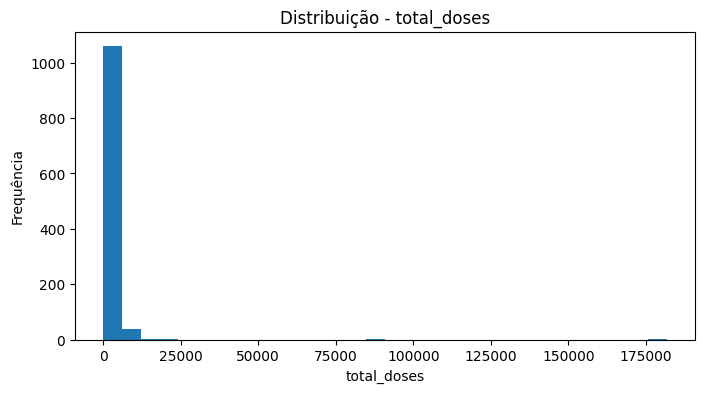

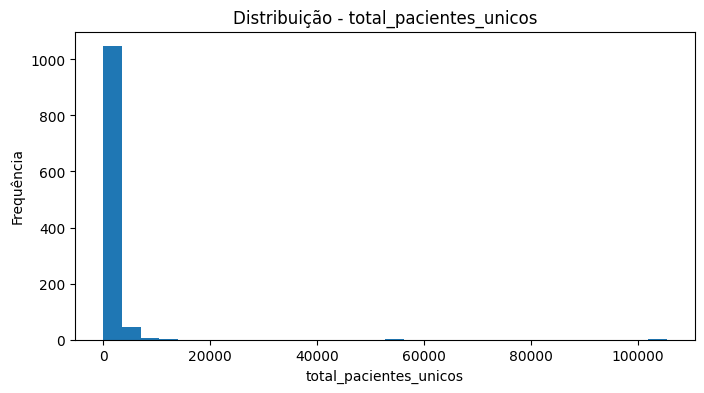

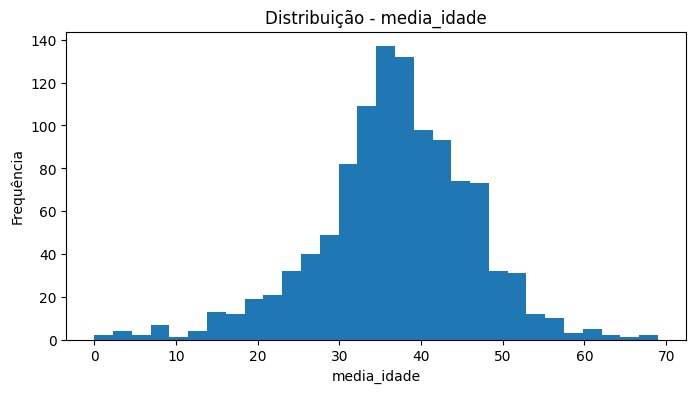

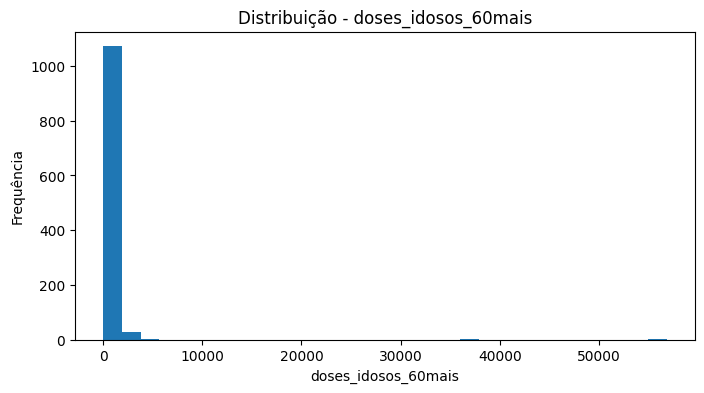

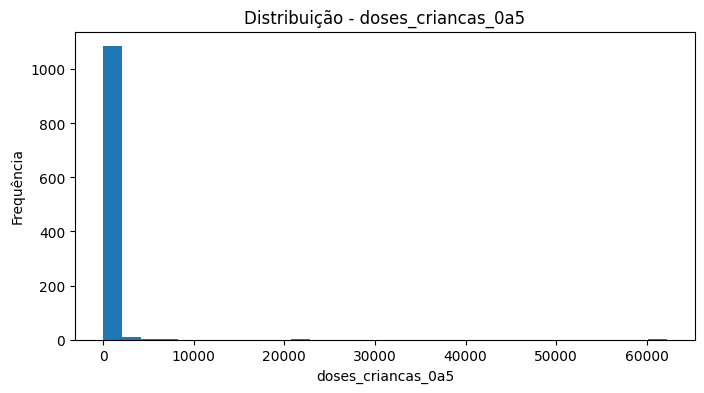

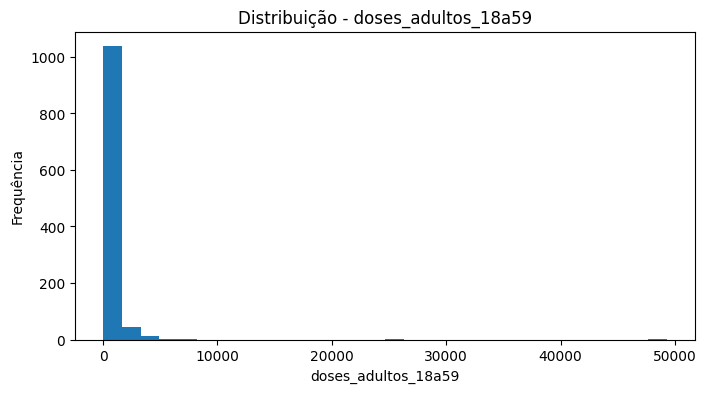

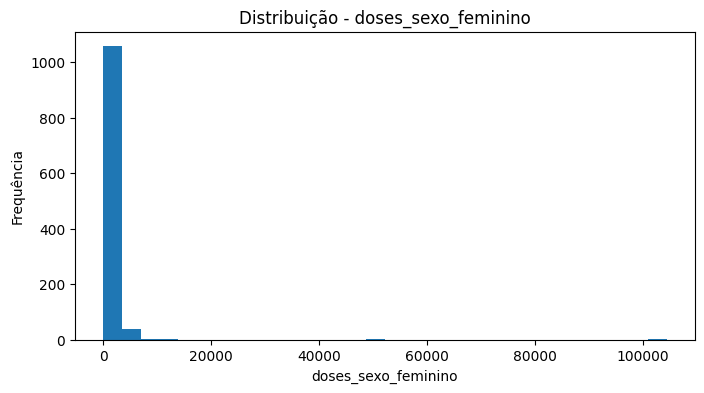

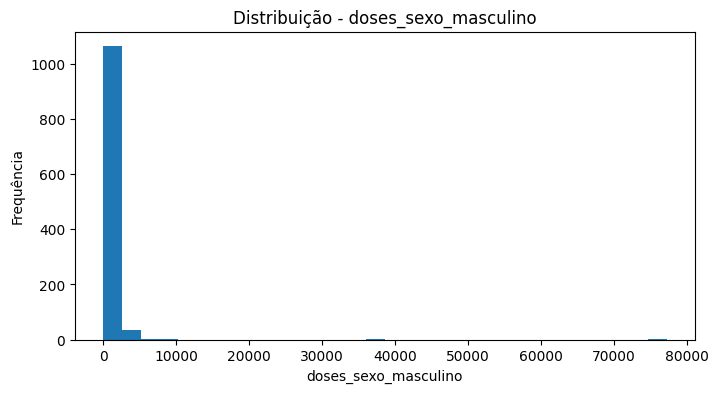

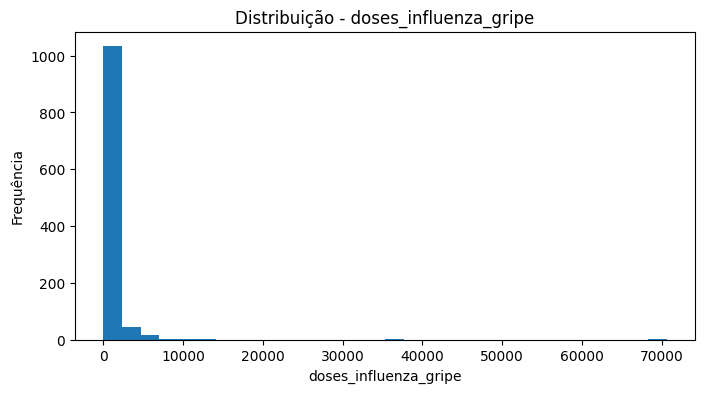

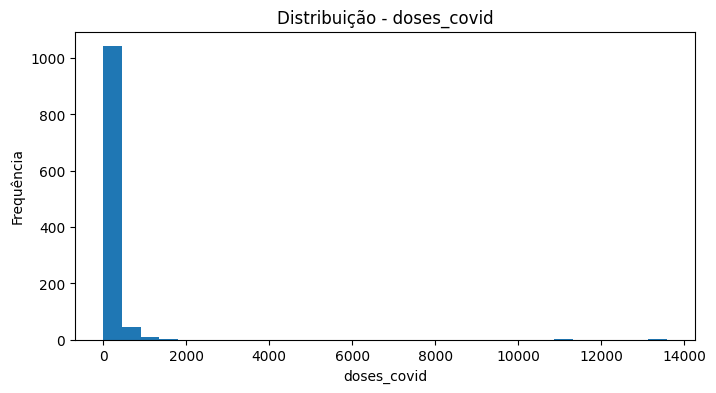

In [17]:
distribuicao_cluster(df_cluster)

A análise das distribuições confirma que praticamente todas as variáveis de contagem da base de clustering apresentam forte assimetria à direita, com grande concentração de CEPs em valores baixos e poucos CEPs com volumes muito elevados. Esse comportamento é visível em total_doses, total_pacientes_unicos, doses por faixa etária, sexo, influenza e Covid, indicando uma cauda longa e a presença de observações extremas. Já media_idade apresenta uma distribuição bem mais equilibrada, concentrada principalmente entre aproximadamente 30 e 50 anos, sem a mesma assimetria observada nas variáveis de volume. Os gráficos reforçam que os valores extremos não parecem ser simples ruídos, mas podem representar CEPs com concentração real de aplicações e, portanto, não devem ser excluídos automaticamente. Entretanto, essa diferença de escala e distribuição pode influenciar fortemente algoritmos baseados em distância, como o K-Means.

In [18]:
corr = correlacao_cluster(df_cluster)

                        total_doses  total_pacientes_unicos  media_idade  \
total_doses                    1.00                    1.00         0.00   
total_pacientes_unicos         1.00                    1.00         0.01   
media_idade                    0.00                    0.01         1.00   
doses_idosos_60mais            0.99                    0.99         0.02   
doses_criancas_0a5             0.99                    0.98        -0.02   
doses_adultos_18a59            0.99                    1.00         0.00   
doses_sexo_feminino            1.00                    1.00         0.00   
doses_sexo_masculino           1.00                    1.00         0.00   
doses_influenza_gripe          0.99                    0.99         0.01   
doses_covid                    0.97                    0.98         0.02   

                        doses_idosos_60mais  doses_criancas_0a5  \
total_doses                            0.99                0.99   
total_pacientes_unicos       

A matriz de correlação mostra que quase todas as variáveis de contagem apresentam correlações extremamente altas entre si, geralmente entre 0,93 e 1,00. total_doses e total_pacientes_unicos, por exemplo, possuem correlação praticamente perfeita, e o mesmo ocorre entre os totais de doses e as variáveis de sexo, faixa etária, influenza e Covid. Isso indica que essas variáveis estão capturando, em grande parte, o mesmo fenômeno: o volume de vacinação de cada CEP. Assim, CEPs com muitas doses tendem naturalmente a apresentar valores elevados em praticamente todas as demais contagens. A principal exceção é media_idade, cuja correlação com as demais variáveis está próxima de zero, indicando que ela representa uma dimensão diferente do comportamento dos CEPs. Para o clustering, esse resultado é importante porque utilizar todas as contagens brutas faria com que várias dimensões redundantes reforçassem repetidamente o efeito do volume nas distâncias calculadas pelo K-Means. Por isso, a próxima etapa deve priorizar a criação de proporções e indicadores relativos, como percentual de doses em crianças, idosos, homens, mulheres, influenza e Covid, além de indicadores como doses por paciente.

In [19]:
top_ceps(df_cluster)

     cep_prefixo_5digitos  total_doses
1101                00091       181688
1100                00090        90170
1097                91787        20385
1099                91790        20066
1094                91520        15474
1082                91250        14571
1089                91260        11576
1077                91750        11087
1063                91420        11081
1092                91920        10896
1093                90840        10241
1090                91510        10010
1091                91910         9956
1098                90010         9450
1072                00094         9381
1083                91740         8946
1076                91720         8701
1071                90250         8410
1096                90050         8144
1095                90040         8046


,cep_prefixo_5digitos,total_doses
1101,00091,181688
1100,00090,90170
1097,91787,20385
1099,91790,20066
1094,91520,15474
1082,91250,14571
1089,91260,11576
1077,91750,11087
1063,91420,11081
1092,91920,10896


A análise dos CEPs com maior volume de vacinação ajuda a explicar os valores extremos observados anteriormente nas distribuições. Os registros 00091 e 00090 apresentam, respectivamente, 181.688 e 90.170 doses, volumes muito superiores aos demais CEPs; o próximo maior, 91787, possui 20.385 doses. Além da diferença de magnitude, os prefixos 00091, 00090 e também 00094 aparentam ser inconsistentes com o padrão dos demais CEPs presentes na base e devem ser investigados antes da modelagem, verificando se correspondem a problemas de preenchimento, transformação ou agregação do campo de CEP. Entre os registros com formato esperado, ainda existe variação relevante de volume, com CEPs como 91787, 91790, 91520 e 91250 apresentando maior concentração de doses.

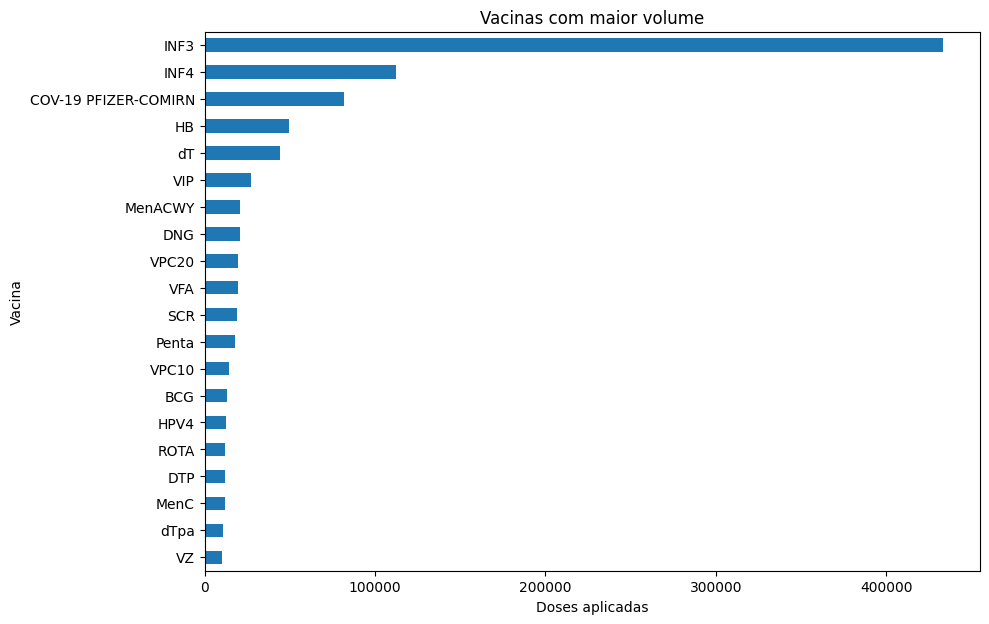

,total_doses_aplicadas
sigla_vacina,
INF3,433266
INF4,112219
COV-19 PFIZER-COMIRN,81991
HB,49415
dT,44263
VIP,27141
MenACWY,20871
DNG,20490
VPC20,19429


In [20]:
ranking_vacinas(df_series)

A distribuição do volume de doses por imunobiológico mostra uma forte concentração em poucas vacinas, com INF3 apresentando volume muito superior às demais, seguida por INF4 e COV-19 PFIZER-COMIRN. Vacinas como HB, dT e VIP aparecem em um segundo grupo de maior utilização, enquanto os demais imunobiológicos possuem volumes progressivamente menores. Esse comportamento é relevante para a etapa de séries temporais, pois indica que nem todas as vacinas possuem o mesmo volume de observações ou a mesma dinâmica de aplicação

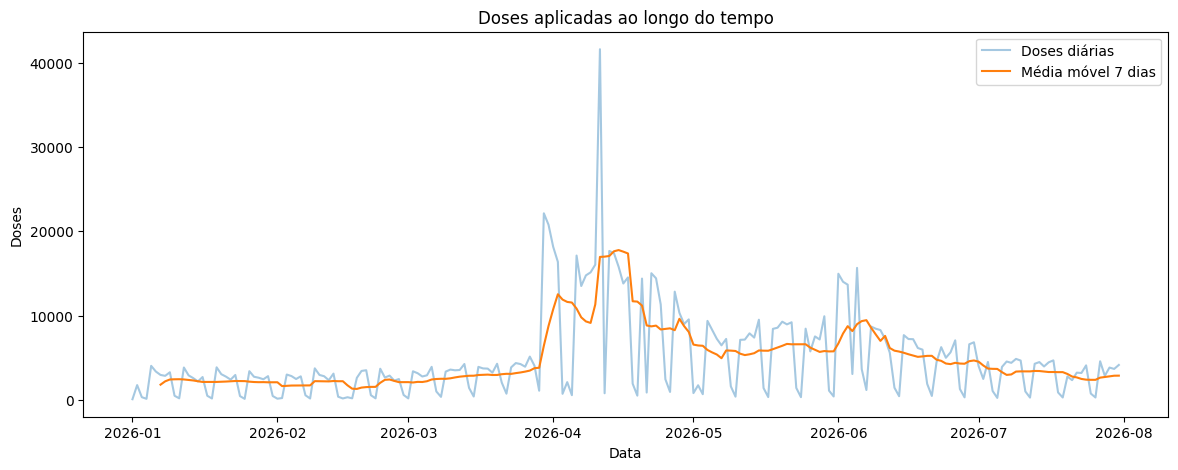

In [21]:
serie = serie_temporal_geral(df_series)

A série temporal geral evidencia uma mudança importante no comportamento da vacinação ao longo do período analisado. Entre janeiro e março de 2026, o volume diário permanece relativamente estável e em níveis mais baixos, com oscilações recorrentes ao longo das semanas. A partir do final de março e início de abril ocorre um crescimento acentuado no número de aplicações, incluindo um pico diário superior a 40 mil doses. A média móvel de 7 dias confirma que esse aumento não se restringe a um único dia, mostrando uma elevação sustentada do volume durante abril. Após esse período, observa-se uma redução gradual, embora ocorram novos aumentos pontuais, especialmente no início de junho. Entre junho e julho, a tendência volta a cair e se aproxima dos níveis observados no início do ano. Também é possível identificar oscilações periódicas entre dias de maior e menor aplicação, sugerindo a existência de um padrão associado ao calendário semanal, hipótese que deve ser investigada na análise por dia da semana.

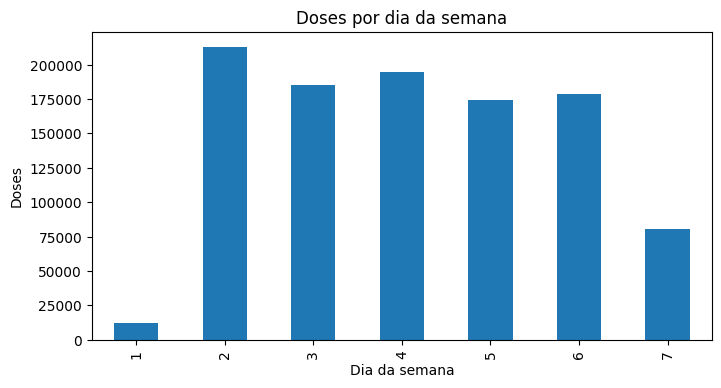

,total_doses_aplicadas
dia_semana,
1,12500
2,213150
3,185432
4,194594
5,174201
6,178722
7,80207


In [22]:
doses_por_dia_semana(df_series)

A análise por dia da semana evidencia uma sazonalidade semanal bastante clara na aplicação das vacinas. Considerando a codificação usual do BigQuery (1 = domingo e 7 = sábado), o maior volume ocorre na segunda-feira, com 213.150 doses, seguido de quarta-feira (194.594), terça-feira (185.432), sexta-feira (178.722) e quinta-feira (174.201). Nos finais de semana há uma redução expressiva, especialmente aos domingos, com apenas 12.500 doses, enquanto aos sábados foram registradas 80.207 aplicações. Esse comportamento ajuda a explicar as oscilações periódicas observadas na série temporal diária e indica a presença de um forte padrão semanal, relacionado provavelmente à rotina de funcionamento dos serviços de vacinação